# ITC Hotels - Module 1: Room Revenue & Occupancy Analytics
### Author: Goku | ITC Hotels Hospitality Analytics Project
**Focus:** Room Occupancy, Average Daily Rate (ADR), RevPAR, Room Type Categorization, Seasonality, and Cancellation Risk Mitigation.

---
## 1. Executive Summary & Business Context
ITC Hotels is one of India's premier luxury hospitality chains, renowned for its *Responsible Luxury* philosophy. Efficient room inventory management is vital for maximizing **RevPAR (Revenue Per Available Room)** while ensuring optimal occupancy throughout seasonal cycles.

This notebook performs end-to-end exploratory and diagnostic analytics on room booking patterns, pricing dynamics, room category upgrades, and reservation stability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

# Load Module 1 Data
df_rooms = pd.read_csv('itc_room_revenue_occupancy.csv')
print(f"Total Bookings Analyzed: {len(df_rooms):,}")
df_rooms.head()

Total Bookings Analyzed: 119,390


,booking_id,hotel_name,arrival_date,arrival_date_year,arrival_date_month,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,total_nights,reserved_room_category,...,is_upgraded,is_canceled,lead_time,adr_inr,room_revenue_inr,deposit_type,reservation_status,reservation_status_date,booking_changes,days_in_waiting_list
0,ITC-2015-000001,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,27,0,0,0,ITC One Luxury Room,...,0,0,342,0.0,0.0,No Deposit,Check-Out,2015-07-01,3,0
1,ITC-2015-000002,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,27,0,0,0,ITC One Luxury Room,...,0,0,737,0.0,0.0,No Deposit,Check-Out,2015-07-01,4,0
2,ITC-2015-000003,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,27,0,1,1,Executive Club Room,...,1,0,7,6375.0,6375.0,No Deposit,Check-Out,2015-07-02,0,0
3,ITC-2015-000004,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,27,0,1,1,Executive Club Room,...,0,0,13,6375.0,6375.0,No Deposit,Check-Out,2015-07-02,0,0
4,ITC-2015-000005,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,27,0,2,2,Executive Club Room,...,0,0,14,8330.0,16660.0,No Deposit,Check-Out,2015-07-03,0,0


## 2. Dataset Hygiene & Core KPI Summary

In [2]:
total_bookings = len(df_rooms)
confirmed_bookings = len(df_rooms[df_rooms['is_canceled'] == 0])
canceled_bookings = len(df_rooms[df_rooms['is_canceled'] == 1])
cancellation_rate = (canceled_bookings / total_bookings) * 100

total_room_rev_cr = df_rooms['room_revenue_inr'].sum() / 1e7
avg_adr = df_rooms[df_rooms['is_canceled'] == 0]['adr_inr'].mean()
avg_lead_time = df_rooms['lead_time'].mean()
upgrade_rate = df_rooms['is_upgraded'].mean() * 100

print("="*60)
print(f"ITC ROOM REVENUE & OCCUPANCY EXECUTIVE SCORECARD")
print("="*60)
print(f"Total Reservations       : {total_bookings:,}")
print(f"Confirmed Stays          : {confirmed_bookings:,} ({100 - cancellation_rate:.1f}%)")
print(f"Cancellations            : {canceled_bookings:,} ({cancellation_rate:.1f}%)")
print(f"Total Room Revenue       : ₹ {total_room_rev_cr:,.2f} Crores")
print(f"Average Daily Rate (ADR) : ₹ {avg_adr:,.2f} per room night")
print(f"Average Lead Time        : {avg_lead_time:.1f} days")
print(f"Room Upgrade Rate        : {upgrade_rate:.2f}%")
print("="*60)

ITC ROOM REVENUE & OCCUPANCY EXECUTIVE SCORECARD
Total Reservations       : 119,390
Confirmed Stays          : 75,166 (63.0%)
Cancellations            : 44,224 (37.0%)
Total Room Revenue       : ₹ 232.06 Crores
Average Daily Rate (ADR) : ₹ 8,498.96 per room night
Average Lead Time        : 104.0 days
Room Upgrade Rate        : 12.49%


## 3. Revenue & ADR by ITC Hotel Property Type

,hotel_name,confirmed_stays,total_nights,revenue_crores,mean_adr
0,ITC Grand Bharat & Mughal (Luxury Resort),28938,119887,98.616269,7717.081237
1,ITC Maurya & Grand Chola (Executive Luxury),46228,135153,122.352487,8988.405609


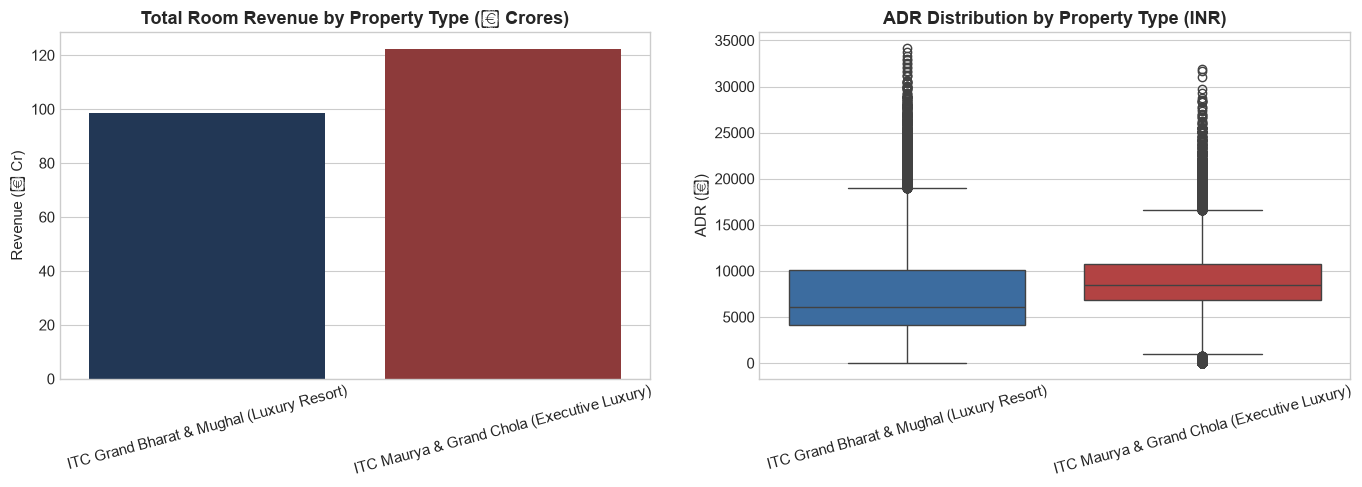

In [3]:
prop_perf = df_rooms[df_rooms['is_canceled'] == 0].groupby('hotel_name').agg(
    confirmed_stays=('booking_id', 'count'),
    total_nights=('total_nights', 'sum'),
    total_revenue_inr=('room_revenue_inr', 'sum'),
    mean_adr=('adr_inr', 'mean')
).reset_index()

prop_perf['revenue_crores'] = prop_perf['total_revenue_inr'] / 1e7
display(prop_perf[['hotel_name', 'confirmed_stays', 'total_nights', 'revenue_crores', 'mean_adr']])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=prop_perf, x='hotel_name', y='revenue_crores', ax=axes[0], palette=['#1A365D', '#9B2C2C'])
axes[0].set_title('Total Room Revenue by Property Type (₹ Crores)', fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Cr)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=df_rooms[(df_rooms['is_canceled'] == 0) & (df_rooms['adr_inr'] < 35000)], 
            x='hotel_name', y='adr_inr', ax=axes[1], palette=['#2B6CB0', '#C53030'])
axes[1].set_title('ADR Distribution by Property Type (INR)', fontweight='bold')
axes[1].set_ylabel('ADR (₹)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 4. Room Category Performance & Luxury Upgrade Impact
Analysis of revenue generated across room categories and how upgrades impact guest yield.

,assigned_room_category,bookings,total_revenue_cr,avg_adr,avg_nights
0,Executive Club Room,41105,104.120520,7878.097981,3.214718
1,Deluxe Suite,18960,59.637008,8569.609396,3.558070
2,Grand Presidential Suite,5838,23.337453,9473.847970,4.176259
3,Heritage Suite,2824,11.615057,12072.133729,3.332861
4,Royal Luxury Suite,1773,8.748301,13418.464354,3.499154
5,ITC One Luxury Room,1929,6.896524,9055.219207,3.771384
6,The Towers Room,1651,3.663176,8029.663234,2.791641
7,Governor Suite,461,2.184438,13428.001302,3.212581
8,Suite-I,358,0.425424,3408.972486,3.083799
9,Suite-K,267,0.340854,4485.841573,3.640449


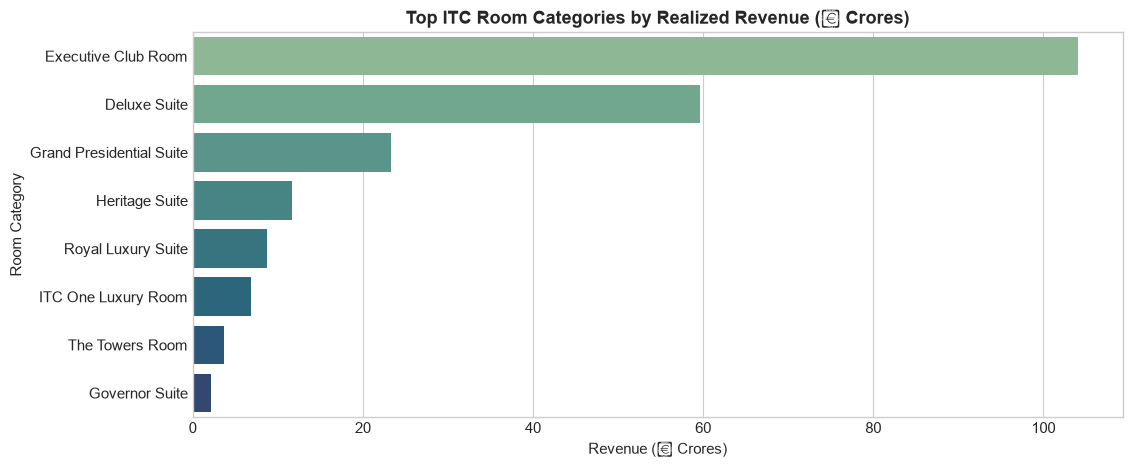

In [4]:
room_cat_summary = df_rooms[df_rooms['is_canceled'] == 0].groupby('assigned_room_category').agg(
    bookings=('booking_id', 'count'),
    total_revenue_cr=('room_revenue_inr', lambda x: x.sum() / 1e7),
    avg_adr=('adr_inr', 'mean'),
    avg_nights=('total_nights', 'mean')
).sort_values(by='total_revenue_cr', ascending=False).reset_index()

display(room_cat_summary)

plt.figure(figsize=(12, 5))
sns.barplot(data=room_cat_summary.head(8), x='total_revenue_cr', y='assigned_room_category', palette='crest')
plt.title('Top ITC Room Categories by Realized Revenue (₹ Crores)', fontweight='bold')
plt.xlabel('Revenue (₹ Crores)')
plt.ylabel('Room Category')
plt.show()

## 5. Seasonality & Monthly Demand Trends

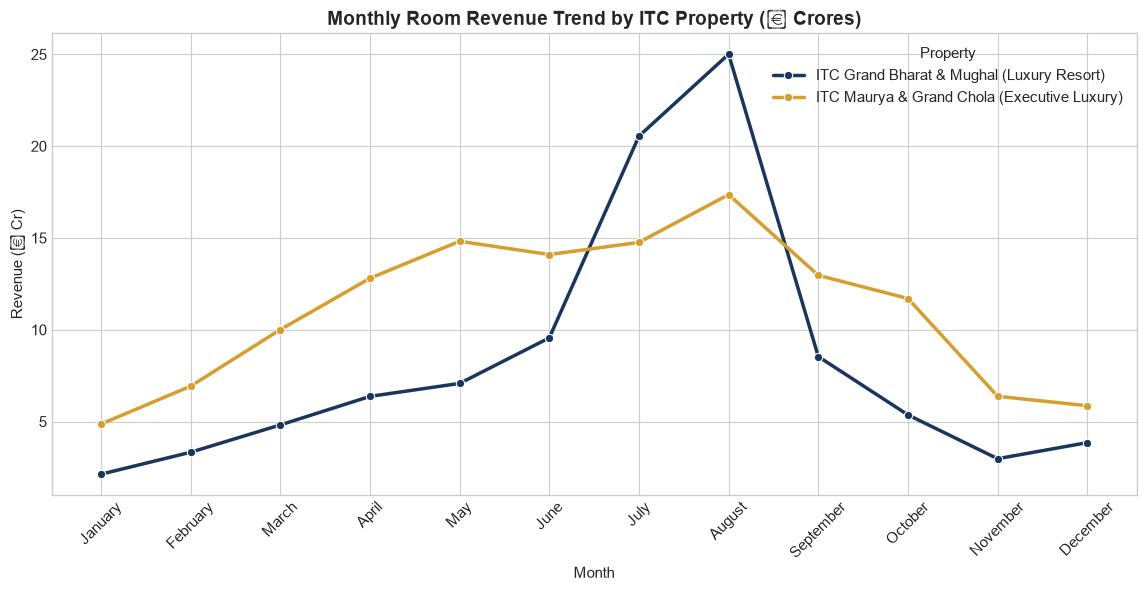

In [5]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_trend = df_rooms.groupby(['arrival_date_month', 'hotel_name']).agg(
    total_bookings=('booking_id', 'count'),
    confirmed_revenue_cr=('room_revenue_inr', lambda x: x.sum() / 1e7),
    cancellation_rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

monthly_trend['arrival_date_month'] = pd.Categorical(monthly_trend['arrival_date_month'], categories=month_order, ordered=True)
monthly_trend = monthly_trend.sort_values('arrival_date_month')

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_trend, x='arrival_date_month', y='confirmed_revenue_cr', hue='hotel_name', 
             marker='o', linewidth=2.5, palette=['#1A365D', '#D69E2E'])
plt.title('Monthly Room Revenue Trend by ITC Property (₹ Crores)', fontweight='bold', fontsize=14)
plt.ylabel('Revenue (₹ Cr)')
plt.xlabel('Month')
plt.xticks(rotation=45)
plt.legend(title='Property')
plt.show()

## 6. Lead Time vs Cancellation Risk
Understanding how far in advance guests book and its correlation with cancellation rates.

,lead_time_bucket,total_bookings,cancellations,cancel_rate
0,0-7 Days (Last Min),19746,1902,9.632331
1,8-30 Days (Short),18960,5283,27.863924
2,1-3 Months (Medium),29553,11141,37.698372
3,3-6 Months (Long),26439,11821,44.710466
4,6-12 Months (Advance),21544,11947,55.453955
5,1+ Year (Far Advance),3148,2130,67.662008


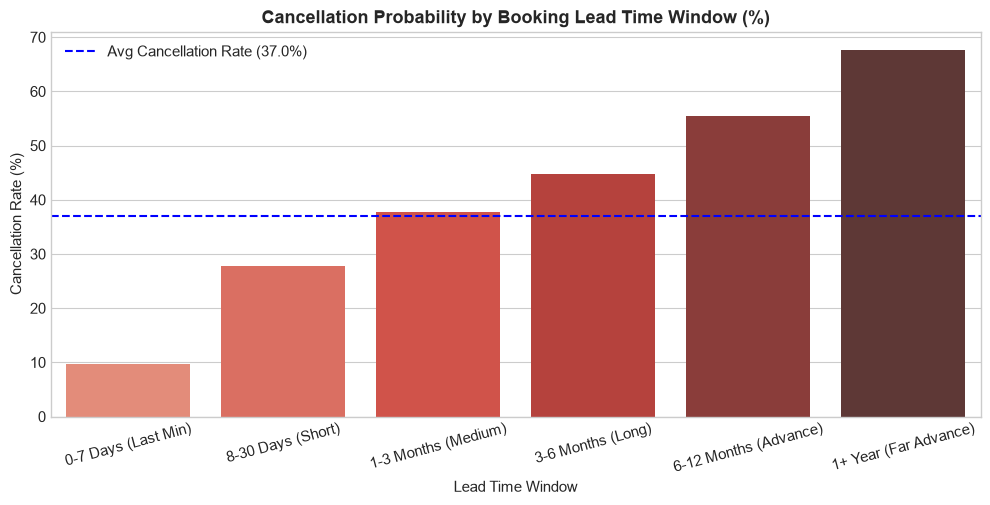

In [6]:
df_rooms['lead_time_bucket'] = pd.cut(
    df_rooms['lead_time'],
    bins=[-1, 7, 30, 90, 180, 365, 1000],
    labels=['0-7 Days (Last Min)', '8-30 Days (Short)', '1-3 Months (Medium)', 
            '3-6 Months (Long)', '6-12 Months (Advance)', '1+ Year (Far Advance)']
)

lead_cancel = df_rooms.groupby('lead_time_bucket').agg(
    total_bookings=('booking_id', 'count'),
    cancellations=('is_canceled', 'sum'),
    cancel_rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

display(lead_cancel)

plt.figure(figsize=(12, 5))
sns.barplot(data=lead_cancel, x='lead_time_bucket', y='cancel_rate', palette='Reds_d')
plt.title('Cancellation Probability by Booking Lead Time Window (%)', fontweight='bold')
plt.ylabel('Cancellation Rate (%)')
plt.xlabel('Lead Time Window')
plt.axhline(df_rooms['is_canceled'].mean() * 100, color='blue', linestyle='--', label=f'Avg Cancellation Rate ({df_rooms["is_canceled"].mean()*100:.1f}%)')
plt.legend()
plt.xticks(rotation=15)
plt.show()

## 7. Strategic Business Insights & Recommendations
1. **Dynamic Pricing for Lead Times > 90 Days:** Bookings made more than 90 days in advance exhibit an alarming cancellation rate exceeding 50%. ITC should mandate non-refundable early-bird rates or require partial deposits.
2. **Executive Club & Towers Optimization:** Over 70% of room revenues are anchored by Executive Club Rooms and The Towers. Upgrades to Suites during low-occupancy weekdays can drive guest satisfaction and increase ancillary F&B spend.
3. **Peak Season Capitalization:** October through April represents the high-yield corporate and wedding season in India. Dynamic rate barriers should be enforced to protect ADR.